## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import torch
from dotenv import load_dotenv

load_dotenv()
DATA_ROOT = Path(os.getenv("DATA_ROOT"))
NIH_DIR = DATA_ROOT / "NIH_Chest_X-Rays"
PROJECT_ROOT = Path.cwd().parent

## 2. Build the Datasets

In [2]:
from src.data import NIH_DISEASES, build_image_paths, load_dev_labels
from src.dataset import NIHDataset
from src.paths import SPLIT_CSV
from src.transforms import build_transforms

df = load_dev_labels(NIH_DIR, SPLIT_CSV)
image_paths = build_image_paths(NIH_DIR)

train_ds = NIHDataset(df[df["split"] == "train"], image_paths, build_transforms(train=True))
val_ds = NIHDataset(df[df["split"] == "val"], image_paths, build_transforms(train=False))

assert (len(train_ds), len(val_ds)) == (75_982, 10_542)
len(train_ds), len(val_ds)

(75982, 10542)


## 3. Inspect One Sample

In [3]:
x, y = train_ds[0]
print("image:", x.shape, x.dtype, f"min={x.min():.2f} max={x.max():.2f} mean={x.mean():.2f}")
print("label:", y.shape, y.dtype)
print("positives:", [d for d, v in zip(NIH_DISEASES, y) if v == 1])

image: torch.Size([3, 224, 224]) torch.float32 min=-2.12 max=2.64 mean=0.08
label: torch.Size([14]) torch.float32
positives: ['Cardiomegaly']


## 4. Look at Augmented Images

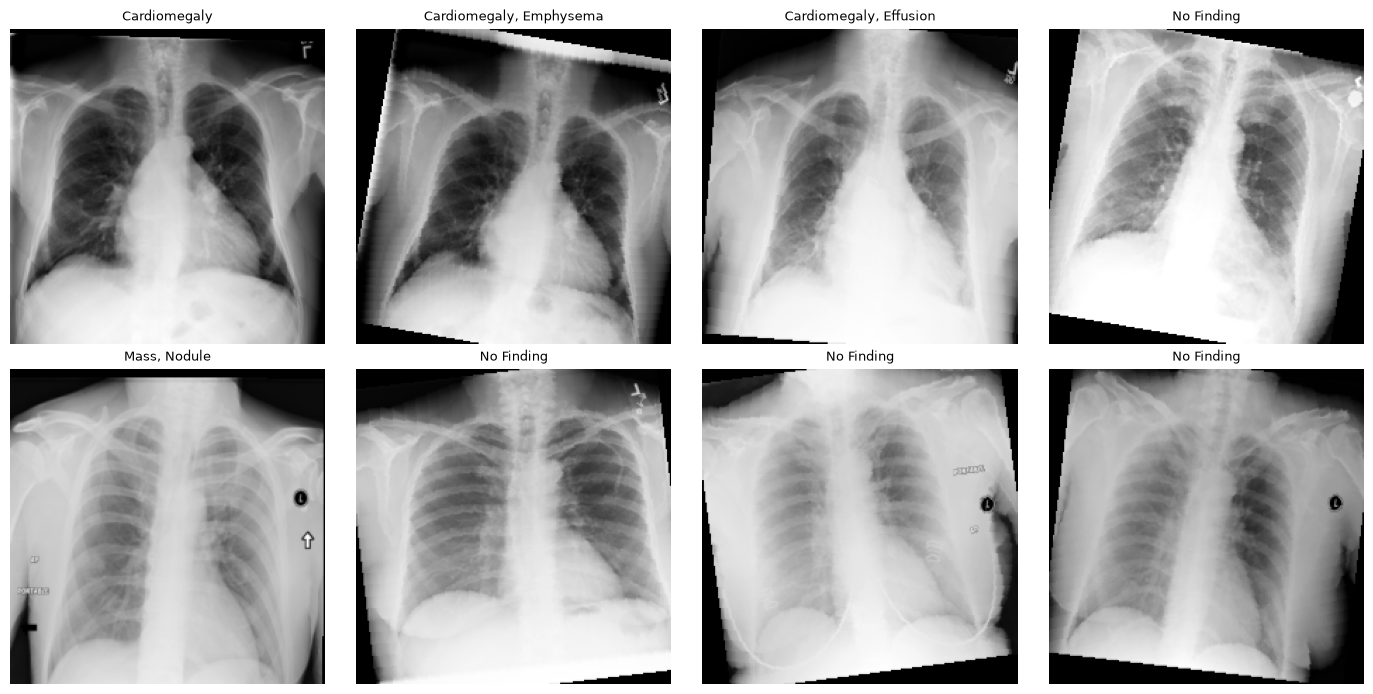

In [4]:
import matplotlib.pyplot as plt

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, idx in zip(axes.flat, range(8)):
    x, y = train_ds[idx]
    img = (x * std + mean).clamp(0, 1)[0]
    labels = [d for d, v in zip(NIH_DISEASES, y) if v == 1] or ["No Finding"]
    ax.imshow(img, cmap="gray")
    ax.set_title(", ".join(labels), fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. DataLoader Throughput

In [5]:
import time
from torch.utils.data import DataLoader

loader = DataLoader(
    train_ds, batch_size=64, shuffle=True,
    num_workers=16, pin_memory=True, persistent_workers=True,
)

it = iter(loader)
next(it)  # warm-up: worker startup + first batch, excluded from timing

n_batches = 50
start = time.perf_counter()
for _ in range(n_batches):
    x, y = next(it)
elapsed = time.perf_counter() - start

rate = n_batches * 64 / elapsed
print(f"{rate:.0f} images/sec  →  ~{len(train_ds) / rate / 60:.1f} min/epoch (data only)")
print(x.shape, y.shape)

650 images/sec  →  ~1.9 min/epoch (data only)
torch.Size([64, 3, 224, 224]) torch.Size([64, 14])


## Dataset decisions
- Grayscale replicated to 3 channels (`convert("RGB")`) to reuse ImageNet-pretrained first-layer weights; also strips alpha from the ~0.5% RGBA PNGs.
- ImageNet mean/std normalization for compatibility with pretrained weights.
- 224×224 input (pretrained resolution). Limitation: ~4.6× downsampling may hurt small findings (Nodule, Mass).
- Train augmentation: ±10° rotation, ±5% translation, ±5% scale, ±10% brightness/contrast. No flips (chest anatomy is not left–right symmetric).
- Val/test: deterministic resize + normalize only.
- Dataset/transforms live in `src/` so Windows spawn-based DataLoader workers can import them.
- DataLoader: 16 workers (of 24 logical cores); steady-state ~700–900 img/s measured after warm-up (varies with cold disk reads). Pre-resized image cache deferred unless the GPU outpaces data loading.
- Test isolation (added 2026-11-05): dev notebooks load data only via `load_dev_labels` (train/val); `NIHDataset` raises on test rows unless `allow_test=True`, which only the test entry point uses. The test row count is documented in `02_split.ipynb` only.